# 02 · Correlation and redundancy pruning

**Goal.** Find subindicators that carry almost the same information and build a "clean" variable set without them.

* Correlation: **Spearman** (ranks), because with 20 countries Pearson is easily driven by one outlier.
* Computed on **real data only**, pair by pair over the countries where both subindicators are observed (at least 10 shared countries).
* One pruning list is applied to **both** A and I, so A-pruned and I-pruned differ only in the data.

**Rule.** Complete-linkage clustering on `1 − |ρ|`, cut at `1 − threshold`, so inside a group *every* pair has `|ρ| ≥ threshold`.
One subindicator per group is kept: the one with the most observed countries (so A does not lose the group to a gap),
then the one least correlated with everything outside the group. Main threshold **0.9**; 0.85 and 0.8 are reported for comparison.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from ilia_explore import data as D, pruning as P, pca as PC, clustering as CL, plots as PL, pipeline as PP

PL.setup_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 3)

In [2]:
codebook = D.load_codebook()
masked = pd.read_csv(D.PROCESSED / "final_masked_wide.csv", index_col=0)
X_real = D.to_matrix(masked)                     # countries x 126, NaN where imputed
corr = P.spearman_pairwise(X_real)
out = D.RESULTS / "pruning"; out.mkdir(parents=True, exist_ok=True)
corr.to_csv(out / "spearman_pairwise_real_data.csv")
n_pairs = len(corr) * (len(corr) - 1) // 2
off = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(f"{n_pairs} pairs; {int(n_pairs - off.size)} without enough shared countries; "
      f"|rho| >= 0.9: {(off.abs() >= 0.9).sum()}, >= 0.8: {(off.abs() >= 0.8).sum()}")

7875 pairs; 16 without enough shared countries; |rho| >= 0.9: 46, >= 0.8: 212


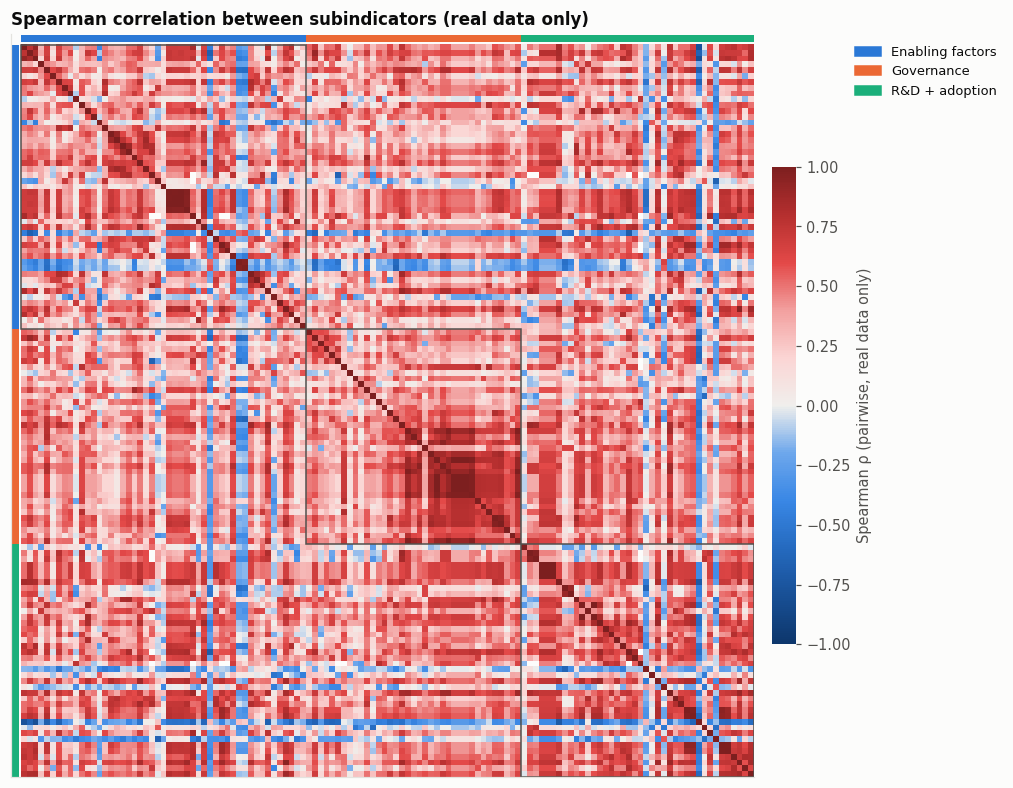

In [3]:
fig = PL.correlation_heatmap(corr, codebook, "Spearman correlation between subindicators (real data only)")
PL.save(fig, "02_correlation_heatmap"); plt.show()

## How many subindicators each threshold keeps

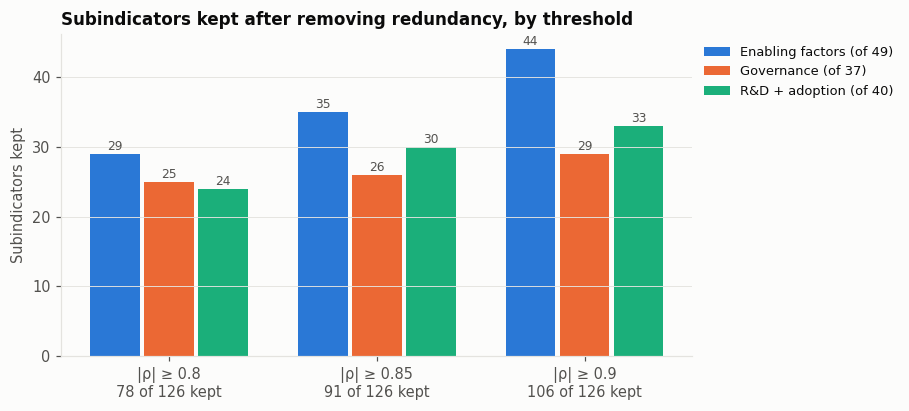

,threshold,kept_total,dropped_total,groups_merged,kept_FH,of_FH,kept_IDA,of_IDA,kept_GOB,of_GOB,kept_without_gaps
0,0.80,78,48,31,29,49,24,40,25,37,58
1,0.85,91,35,22,35,49,30,40,26,37,61
2,0.90,106,20,13,44,49,33,40,29,37,70


In [4]:
complete = codebook["n_imputed"] == 0
summary = P.threshold_summary(corr, codebook["n_observed"], codebook["dim_code"], (0.8, 0.85, 0.9), complete)
summary.to_csv(out / "threshold_summary.csv", index=False)
fig = PL.threshold_bars(summary); PL.save(fig, "02_threshold_summary"); plt.show()
summary

In [5]:
tables = {}
for t in (0.8, 0.85, 0.9):
    tab = P.prune(corr, codebook["n_observed"], t).join(
        codebook[["dim_code", "subdim_code", "subindicador", "n_observed"]])
    tab.to_csv(out / f"pruning_table_rho{t:.2f}.csv")
    tables[t] = tab

## Redundant groups at |ρ| ≥ 0.9

In [6]:
t90 = tables[0.9]
groups = t90[t90["group_size"] > 1].sort_values(["group", "kept"], ascending=[True, False])
groups[["group", "kept", "dim_code", "n_observed", "min_abs_rho_in_group", "subindicador"]]

,group,kept,dim_code,n_observed,min_abs_rho_in_group,subindicador
code,,,,,,
FH.INF.19,18,True,FH,20,0.960,Memoria de GPUs
FH.INF.18,18,False,FH,20,0.966,Capacidad de GPUs
FH.INF.20,18,False,FH,20,0.959,Número de GPUs
FH.INF.21,18,False,FH,20,0.959,Capacidad de CPUs
FH.DAT.01,24,True,FH,18,0.911,Disponibilidad Barómetro de Datos
FH.DAT.03,24,False,FH,18,0.911,Gobernanza Barómetro de Datos
FH.TAL.04,34,True,FH,18,0.964,Habilidad en Inglés (Puntaje)
FH.TAL.05,34,False,FH,18,0.964,Habilidad de Inglés en Mujeres (Puntaje)
FH.TAL.12,41,True,FH,20,0.951,Programas de Magíster en IA en Universidades Ranking QS (Cantidad por M. de hab.)


In [7]:
cross = groups.groupby("group")["dim_code"].nunique()
print("Groups mixing dimensions:", list(cross[cross > 1].index))

Groups mixing dimensions: [41]


## Pruned matrices

In [8]:
kept = t90.index[t90["kept"]]
A = D.load_processed("A-full"); I = D.load_processed("I-full")
A_pruned = A[[c for c in A.columns if c in set(kept)]]
I_pruned = I[[c for c in I.columns if c in set(kept)]]
A_pruned.to_csv(D.PROCESSED / "A-pruned.csv"); I_pruned.to_csv(D.PROCESSED / "I-pruned.csv")
shape = pd.DataFrame({c: {"subindicators": m.shape[1], **m.columns.map(codebook["dim_code"]).value_counts().to_dict()}
                      for c, m in {"A-full": A, "A-pruned": A_pruned, "I-full": I, "I-pruned": I_pruned}.items()}).T
shape.to_csv(D.RESULTS / "configuration_sizes.csv")
shape

,subindicators,GOB,FH,IDA
A-full,86,34,26,26
A-pruned,70,26,23,21
I-full,126,37,49,40
I-pruned,106,29,44,33


## Reading the results

* **At |ρ| ≥ 0.9, 20 subindicators fall into 13 redundant groups.** 106 subindicators remain (**I-pruned**); 70 of them have no gaps (**A-pruned**).
  Lower thresholds remove much more: 91 kept at 0.85, 78 at 0.8.
* **The groups are intuitive:** GPU memory, capacity and count with CPU capacity; AI adoption in large, medium and small firms
  (ρ = 1.00, effectively one variable); English proficiency overall and for women; consistent AI research overall and by women authors;
  AI publications and active AI researchers; and the yes/no national-strategy flags in governance, which collapse into a few groups.
* One group crosses dimensions: AI master's programmes (FH.TAL.12) with participation in side tracks (IDA.INV.10).
* **Some subindicators run against the general level** (blue stripes in the heatmap): researcher productivity (IDA.INV.03),
  relative IXP interconnection (FH.INF.25), English proficiency (FH.TAL.04/05), open-source productivity (IDA.IDI.08) and the share of women AI authors (IDA.INV.06).
  These are mostly ratios where small or low-output countries score high. The values were checked against the source data and are kept;
  they load negatively on PC1.